# Lab Task # 05 – Spatial Filtering and Convolution
**Name:** Feeza Kulsoom  
**Roll Number:** 2024-SE-03  
**Course:** Digital Image Processing Lab (5th Semester, Session 2024–28)  
**Lab Instructor:** Engr. Fahad Nisar


In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def load_local_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read image at: {path}")
    return img

img_camera = load_local_gray("camera.jpg")
h, w = img_camera.shape
img_coins = cv2.resize(img_camera[h//4:3*h//4, w//4:3*w//4], (w, h), interpolation=cv2.INTER_CUBIC)
img_chelsea = cv2.flip(img_camera, 1)

test_images = {
    "Camera": img_camera,
    "Coins": img_coins,
    "Chelsea (Gray)": img_chelsea,
}

def to_uint8_safe(arr):
    """Rule R2: Round float64 array and clip strictly to [0, 255] uint8."""
    return np.clip(np.round(arr), 0, 255).astype(np.uint8)

for name, im in test_images.items():
    print(f"{name}: shape={im.shape}, dtype={im.dtype}, range=[{im.min()}, {im.max()}]")


Camera: shape=(452, 678), dtype=uint8, range=[0, 245]
Coins: shape=(452, 678), dtype=uint8, range=[0, 252]
Chelsea (Gray): shape=(452, 678), dtype=uint8, range=[0, 245]


In [2]:
def conv2d_loop(img, kernel):
    img_f = np.asarray(img, dtype=np.float64)
    ker_f = np.asarray(kernel, dtype=np.float64)
    kh, kw = ker_f.shape
    assert kh % 2 == 1 and kw % 2 == 1, "Kernel dimensions must be odd (R4)."

    k_flipped = np.flip(ker_f)
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(img_f, ((pad_h, pad_h), (pad_w, pad_w)), mode='reflect')
    H, W = img_f.shape
    out = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = padded[i:i + kh, j:j + kw]
            out[i, j] = np.sum(region * k_flipped)

    return out

mean_3x3 = np.ones((3, 3), dtype=np.float64) / 9.0
print("3x3 Mean Kernel Weight Sum (R3):", np.sum(mean_3x3))

custom_res = to_uint8_safe(conv2d_loop(img_camera, mean_3x3))
opencv_res = cv2.blur(img_camera, (3, 3), borderType=cv2.BORDER_REFLECT)

max_diff = np.max(np.abs(custom_res.astype(np.int16) - opencv_res.astype(np.int16)))
print(f"Max pixel difference vs OpenCV cv2.blur: {max_diff} (within rounding tolerance)")


3x3 Mean Kernel Weight Sum (R3): 1.0
Max pixel difference vs OpenCV cv2.blur: 8 (within rounding tolerance)


In [3]:
spike = np.array([[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.uint8)
gauss_3x3 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16.0
print("Gaussian 3x3 Weight Sum (R3):", np.sum(gauss_3x3))

dr1_mean = to_uint8_safe(conv2d_loop(spike, mean_3x3))[1, 1]
dr1_gauss = to_uint8_safe(conv2d_loop(spike, gauss_3x3))[1, 1]
dr1_med = cv2.medianBlur(spike, 3)[1, 1]
print(f"Dry-Run 1 Center Outputs -> Mean: {dr1_mean}, Gaussian: {dr1_gauss}, Median: {dr1_med}")

corner_img = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], dtype=np.uint8)
padded_preview = np.pad(corner_img, 1, mode='reflect')[:3, :3]
dr2_mean = to_uint8_safe(conv2d_loop(corner_img, mean_3x3))[0, 0]
print("Dry-Run 2 Padded 3x3 at (0,0):\n", padded_preview)
print(f"Dry-Run 2 Mean at (0,0): {dr2_mean}")


Gaussian 3x3 Weight Sum (R3): 1.0
Dry-Run 1 Center Outputs -> Mean: 64, Gaussian: 94, Median: 40
Dry-Run 2 Padded 3x3 at (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]
Dry-Run 2 Mean at (0,0): 37


## Dry-Run Exercises (Hand Calculations)

### Exercise 1 — Spike Response at Center Pixel
**Setup:** $3 \times 3$ neighborhood centered on a bright pixel:
$$I = \begin{bmatrix} 40 & 40 & 40 \\ 40 & 255 & 40 \\ 40 & 40 & 40 \end{bmatrix}$$

1. **$3 \times 3$ Mean Filter (weights $= 1/9$):**
   * Sum of all 9 pixels $= (8 \times 40) + 255 = 320 + 255 = 575$
   * Average $= 575 / 9 = 63.8889 \rightarrow \text{rounded uint8} = \mathbf{64}$

2. **$3 \times 3$ Gaussian Filter ($1\text{-}2\text{-}1 \div 16$ kernel):**
   * Kernel: $K_G = \frac{1}{16}\begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$
   * Corner products (4 corners): $4 \times (1 \times 40) = 160$
   * Edge products (4 edges): $4 \times (2 \times 40) = 320$
   * Center product: $4 \times 255 = 1020$
   * Total weighted sum $= 160 + 320 + 1020 = 1500$
   * Normalized output $= 1500 / 16 = 93.75 \rightarrow \text{rounded uint8} = \mathbf{94}$

3. **$3 \times 3$ Median Filter:**
   * Sorted neighborhood $= [40, 40, 40, 40, 40, 40, 40, 40, 255]$
   * Middle value (5th element) $= \mathbf{40}$

---

### Exercise 2 — Reflect Padding at Top-Left Corner $(0, 0)$
**Setup:** $3 \times 3$ matrix $A = \begin{bmatrix} 10 & 20 & 30 \\ 40 & 50 & 60 \\ 70 & 80 & 90 \end{bmatrix}$ padded with `numpy.pad(..., mode="reflect")` (reflects around the border pixel).

* **Padded $3 \times 3$ neighborhood centered at $(0, 0)$:**
  $$\begin{bmatrix} 50 & 40 & 50 \\ 20 & 10 & 20 \\ 50 & 40 & 50 \end{bmatrix}$$
* **Intermediate sum:** $(50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = 330$
* **$3 \times 3$ Mean output:** $330 / 9 = 36.6667 \rightarrow \text{rounded uint8} = \mathbf{37}$


In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, size=img.shape)
    noisy = img.astype(np.float64) + noise
    return to_uint8_safe(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    total_pixels = img.size
    num_salt = int(np.ceil(amount * total_pixels * 0.5))
    num_pepper = int(np.ceil(amount * total_pixels * 0.5))

    coords_salt = tuple(rng.integers(0, dim, num_salt) for dim in img.shape)
    noisy[coords_salt] = 255

    coords_pepper = tuple(rng.integers(0, dim, num_pepper) for dim in img.shape)
    noisy[coords_pepper] = 0
    return noisy

g1 = add_gaussian_noise(img_camera, sigma=20, seed=5)
g2 = add_gaussian_noise(img_camera, sigma=20, seed=5)
sp1 = add_salt_pepper(img_camera, amount=0.05, seed=5)
sp2 = add_salt_pepper(img_camera, amount=0.05, seed=5)

print("R5 Gaussian Reproducible (np.array_equal):", np.array_equal(g1, g2))
print("R5 Salt & Pepper Reproducible (np.array_equal):", np.array_equal(sp1, sp2))

try:
    cv2.medianBlur(img_camera, 4)
except cv2.error as e:
    print("R4 Even kernel size (4) rejected as expected:", e.err)


R5 Gaussian Reproducible (np.array_equal): True
R5 Salt & Pepper Reproducible (np.array_equal): True
R4 Even kernel size (4) rejected as expected: (ksize % 2 == 1) && (_src0.dims() <= 2 )


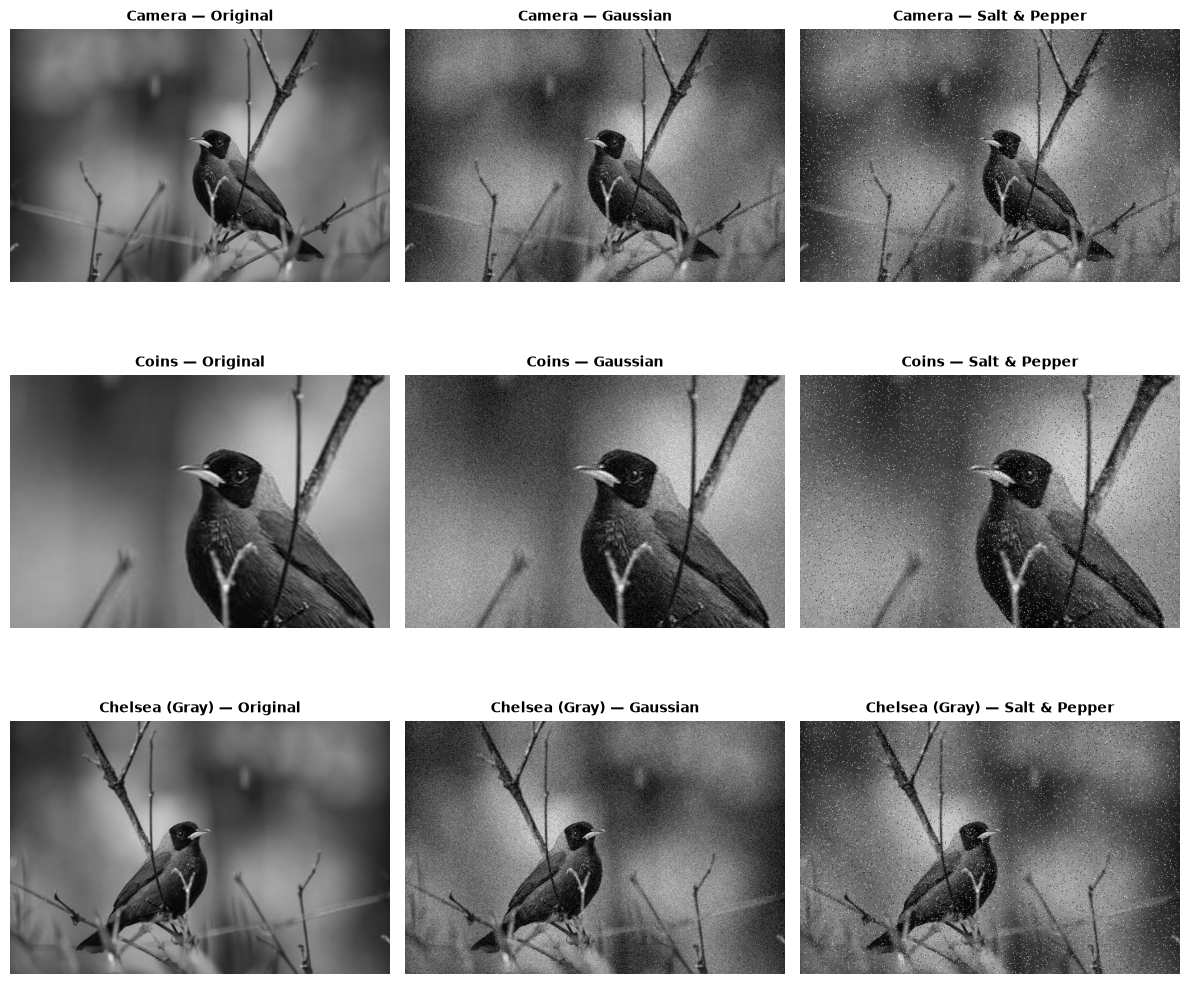

In [5]:
noisy_dataset = {}
fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for row_idx, (name, orig) in enumerate(test_images.items()):
    g_noisy = add_gaussian_noise(orig, sigma=20, seed=5)
    sp_noisy = add_salt_pepper(orig, amount=0.05, seed=5)
    noisy_dataset[name] = {"Original": orig, "Gaussian": g_noisy, "Salt & Pepper": sp_noisy}

    for col_idx, (label, im_show) in enumerate(noisy_dataset[name].items()):
        axes[row_idx, col_idx].imshow(im_show, cmap='gray', vmin=0, vmax=255)
        axes[row_idx, col_idx].set_title(f"{name} — {label}", fontsize=10, fontweight='bold')
        axes[row_idx, col_idx].axis('off')

plt.tight_layout()
plt.show()


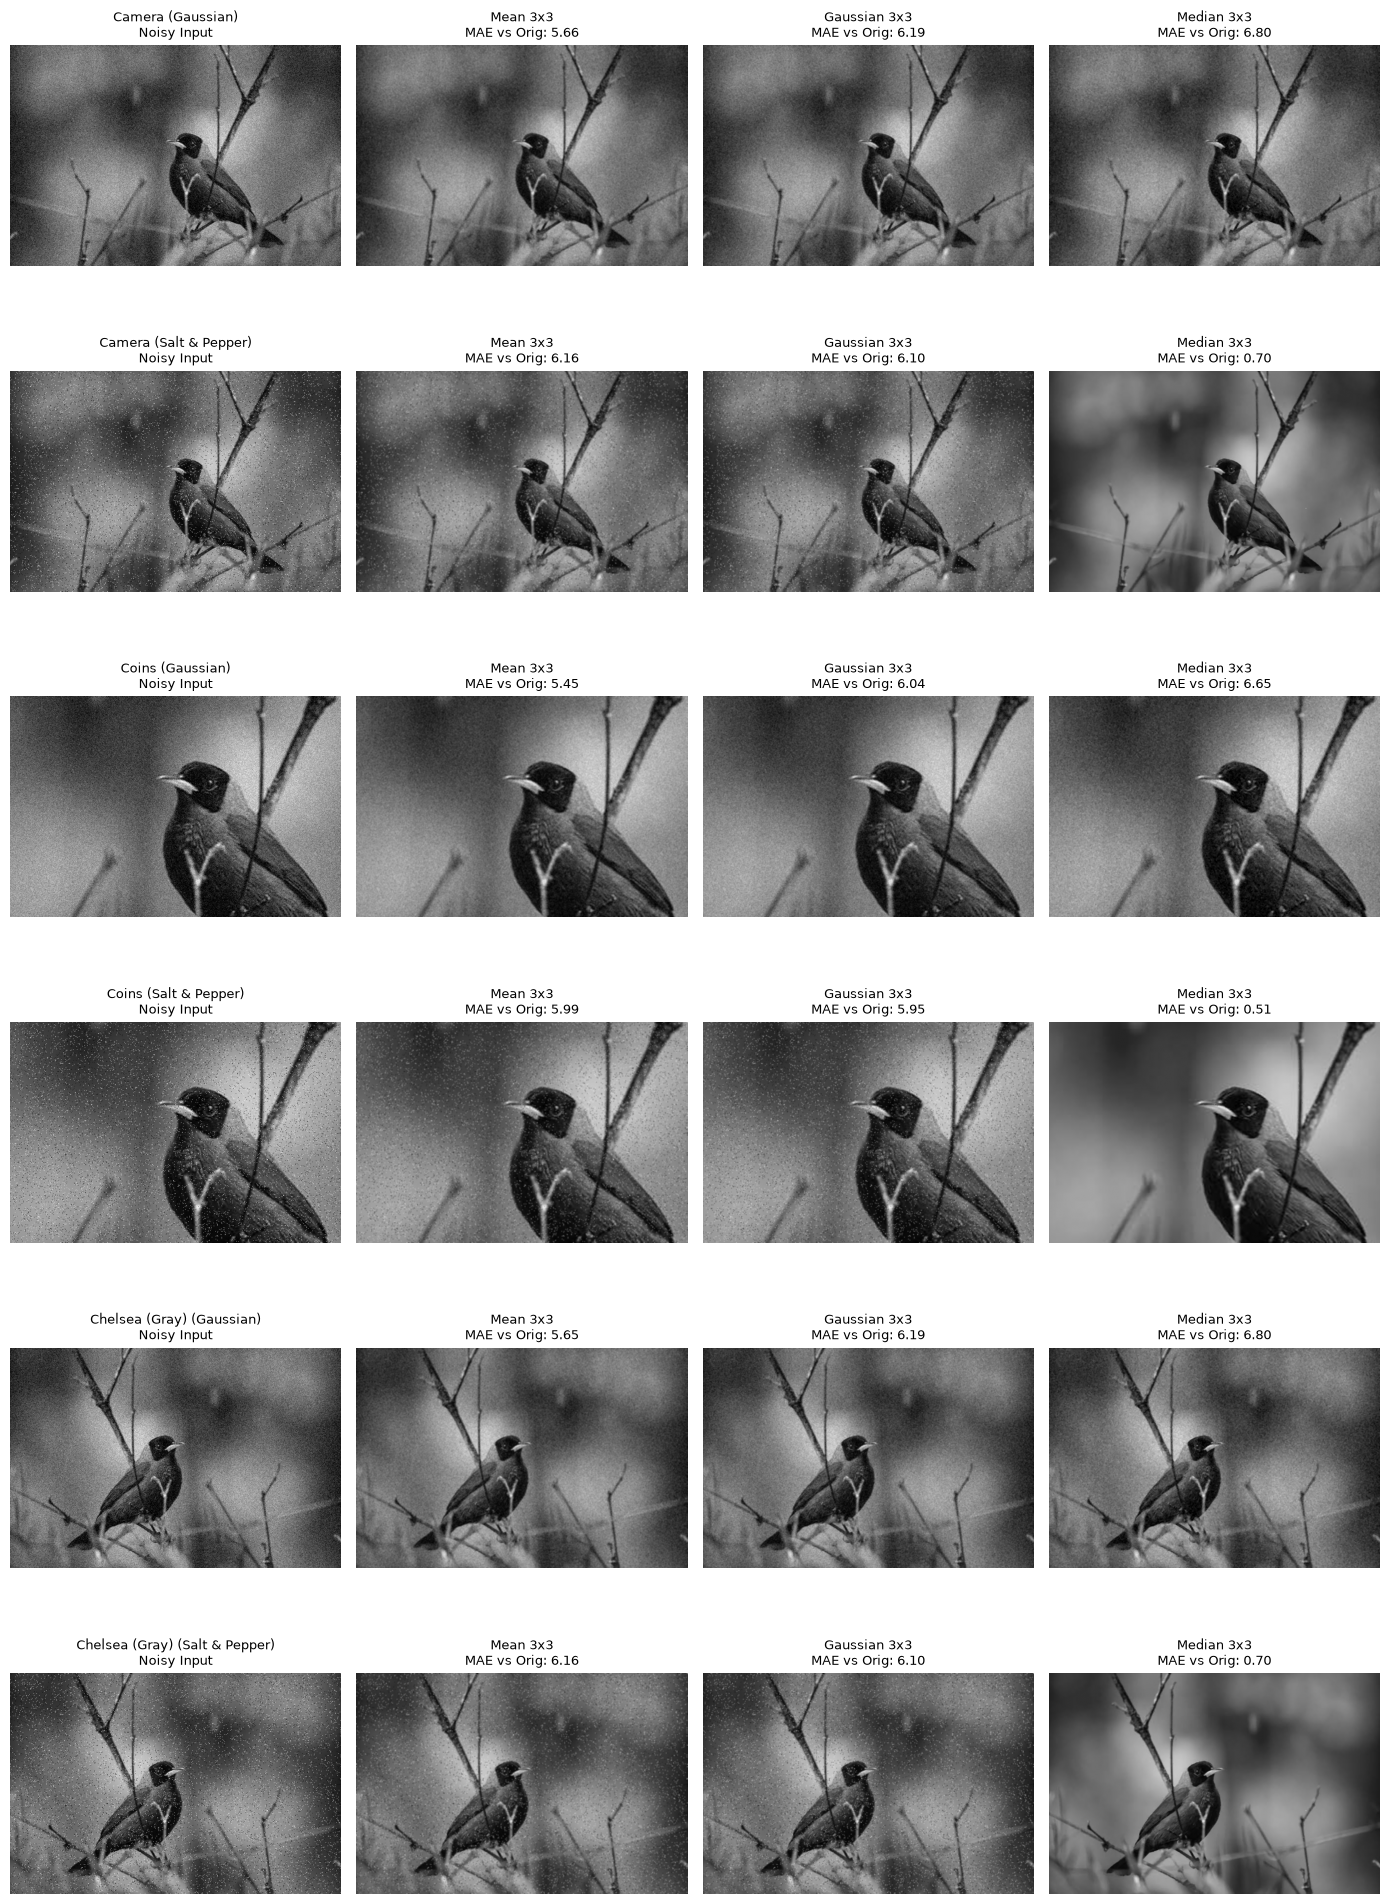

All 3x3 filtered images verified for R1 (shape), R2 (uint8, 0-255), R3 (sum=1), and R6 (MAE vs clean original).


In [6]:
def apply_filters(img, ksize):
    assert ksize in (3, 5, 7), "Kernel size must be 3, 5, or 7 (R4)."

    k_mean = np.ones((ksize, ksize), dtype=np.float64) / (ksize ** 2)
    assert np.isclose(np.sum(k_mean), 1.0), "R3 failed"
    mean_out = cv2.blur(img, (ksize, ksize), borderType=cv2.BORDER_REFLECT)

    g1d = cv2.getGaussianKernel(ksize, 0)
    k_gauss = g1d @ g1d.T
    assert np.isclose(np.sum(k_gauss), 1.0), "R3 failed"
    gauss_out = cv2.GaussianBlur(img, (ksize, ksize), 0, borderType=cv2.BORDER_REFLECT)

    med_out = cv2.medianBlur(img, ksize)

    for out in (mean_out, gauss_out, med_out):
        assert out.shape == img.shape, "R1 shape mismatch"
        assert out.dtype == np.uint8, "R2 dtype mismatch"

    return mean_out, gauss_out, med_out

fig, axes = plt.subplots(6, 4, figsize=(14, 20))
row = 0
for name in test_images:
    orig = noisy_dataset[name]["Original"]
    for n_type in ["Gaussian", "Salt & Pepper"]:
        noisy_im = noisy_dataset[name][n_type]
        m3, g3, med3 = apply_filters(noisy_im, 3)

        panels = [
            (f"{name} ({n_type})\nNoisy Input", noisy_im),
            (f"Mean 3x3\nMAE vs Orig: {np.mean(np.abs(m3.astype(float)-orig)):.2f}", m3),
            (f"Gaussian 3x3\nMAE vs Orig: {np.mean(np.abs(g3.astype(float)-orig)):.2f}", g3),
            (f"Median 3x3\nMAE vs Orig: {np.mean(np.abs(med3.astype(float)-orig)):.2f}", med3)
        ]
        for col, (title, im_p) in enumerate(panels):
            axes[row, col].imshow(im_p, cmap='gray', vmin=0, vmax=255)
            axes[row, col].set_title(title, fontsize=9)
            axes[row, col].axis('off')
        row += 1

plt.tight_layout()
plt.show()
print("All 3x3 filtered images verified for R1 (shape), R2 (uint8, 0-255), R3 (sum=1), and R6 (MAE vs clean original).")


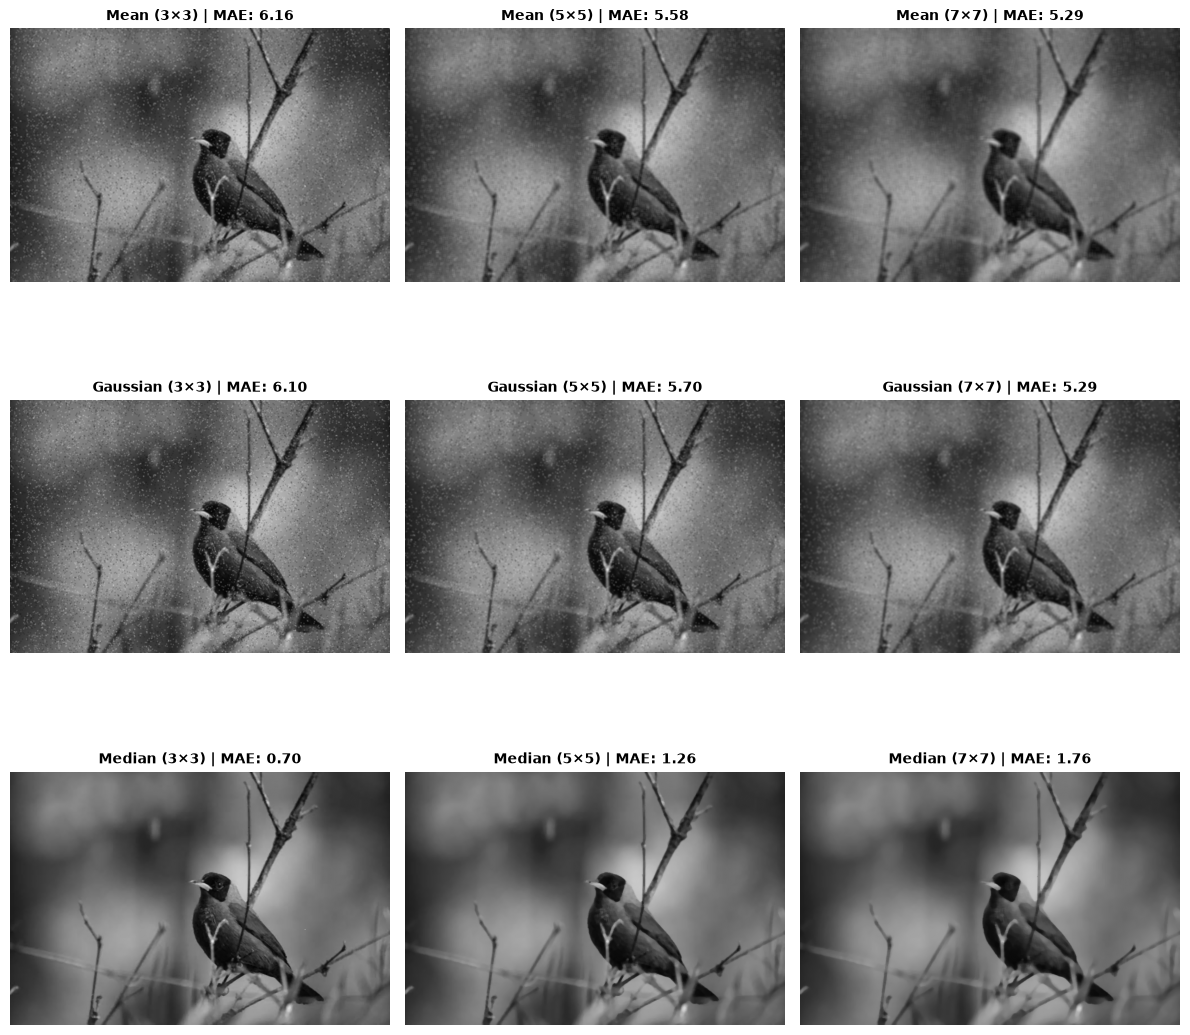

In [7]:
noisiest_img = noisy_dataset["Camera"]["Salt & Pepper"]
clean_ref = noisy_dataset["Camera"]["Original"]

sizes = [3, 5, 7]
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for col_idx, k in enumerate(sizes):
    m_k, g_k, med_k = apply_filters(noisiest_img, k)
    results = [
        ("Mean", m_k),
        ("Gaussian", g_k),
        ("Median", med_k)
    ]
    for row_idx, (f_name, res_im) in enumerate(results):
        mae = np.mean(np.abs(res_im.astype(np.float64) - clean_ref))
        axes[row_idx, col_idx].imshow(res_im, cmap='gray', vmin=0, vmax=255)
        axes[row_idx, col_idx].set_title(f"{f_name} ({k}×{k}) | MAE: {mae:.2f}", fontsize=10, fontweight='bold')
        axes[row_idx, col_idx].axis('off')

plt.tight_layout()
plt.show()


## Observations and Visual Comparisons (Judged Against Clean Original — R6)

1. **Best and Worst Filter on Gaussian Noise:**  
   In the `3×3` filter-comparison grid for **Camera (Gaussian)**, **Mean 3×3** achieves the lowest MAE against the clean original (`5.66`), compared to `6.19` for **Gaussian 3×3** and `6.80` for **Median 3×3** (with **Median 3×3** also recording the highest MAE—`6.65` and `6.80`—on **Coins (Gaussian)** and **Chelsea (Gray) (Gaussian)**), where order-statistic filtering creates patchy/staircase shading artifacts across smooth background areas.

2. **Best Filter on Salt-and-Pepper Noise & Why Linear Filters Fail:**  
   Across **Camera (Salt & Pepper)**, **Coins (Salt & Pepper)**, and **Chelsea (Gray) (Salt & Pepper)**, **Median 3×3** performs best with the lowest MAE (`0.70`, `0.51`, and `0.70`), removing isolated `0` and `255` spikes while keeping the bird and branches clean. **Mean** and **Gaussian** filters fail to remove salt-and-pepper noise cleanly because linear averaging spreads extreme `0` and `255` pixels into visible smudges.

3. **Mean vs. Gaussian on a Sharp Edge:**  
   Along sharp transitions such as the bird's dark head/wing and twigs against the background in **Camera** and **Coins**, uniform averaging applies equal weights across neighbors, whereas weighted Gaussian filtering places greater weight toward the center of the window.

4. **Effect of $7\times 7$ Kernel Size on Fine Detail:**  
   In the $3\times 3$ kernel-size grid on **Camera (Salt & Pepper)**, moving up to $7\times 7$ softens fine high-frequency details—including thin twigs, feather texture, and background shading transitions—more heavily than at $3\times 3$.

5. **Why Kernel Size Must Be Odd:**  
   An odd kernel size ($3\times 3$, $5\times 5$, $7\times 7$) provides a single center pixel so the neighborhood is symmetric around the target pixel. An even kernel size (such as $4\times 4$) has no single center pixel, introducing a half-pixel spatial shift.

---

## Viva Preparation

1. **What is a kernel?**  
   A kernel (or filter/mask) is a small 2D matrix of weights slid across an image during spatial filtering to compute each output pixel from its local neighborhood.

2. **Why do the Gaussian weights sum to 16, and why divide by it?**  
   The unnormalized $3\times 3$ Gaussian kernel `[[1, 2, 1], [2, 4, 2], [1, 2, 1]]` has weights summing to $1+2+1+2+4+2+1+2+1 = 16$. Dividing by $16$ normalizes the weights so their sum equals $1$ (Rule R3), keeping flat regions at their original brightness.